# **Pizza VS Steak (Binary Classification)**

In [1]:
import datetime
print(f"Notebook last run (end-to-end): {datetime.datetime.now()}")

Notebook last run (end-to-end): 2025-09-29 13:48:34.739624


# **Get and download the dataset**

In [2]:
import zipfile

# Download zip file of pizza_steak images
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip

# Unzip the downloaded file
zip_ref = zipfile.ZipFile("pizza_steak.zip", "r")
zip_ref.extractall()
zip_ref.close()

--2025-09-29 13:48:51--  https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.135.207, 192.178.163.207, 173.194.202.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.135.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 109540975 (104M) [application/zip]
Saving to: ‘pizza_steak.zip.1’

pizza_steak.zip.1   100%[===================>] 104.47M   198MB/s    in 0.5s    

2025-09-29 13:48:52 (198 MB/s) - ‘pizza_steak.zip.1’ saved [109540975/109540975]



In [3]:
import os

# Walk through pizza_steak directory and list number of files
for dirpath, dirnames, filenames in os.walk("pizza_steak"):
  print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

There are 2 directories and 0 images in 'pizza_steak'.
There are 2 directories and 0 images in 'pizza_steak/train'.
There are 0 directories and 750 images in 'pizza_steak/train/steak'.
There are 0 directories and 750 images in 'pizza_steak/train/pizza'.
There are 2 directories and 0 images in 'pizza_steak/test'.
There are 0 directories and 250 images in 'pizza_steak/test/steak'.
There are 0 directories and 250 images in 'pizza_steak/test/pizza'.


In [4]:
# Another way to find out how many images are in a file
num_steak_images_train = len(os.listdir("pizza_steak/train/steak"))

num_steak_images_train

750

In [5]:
# Another way to find out how many images are in a file
num_pizza_images_train = len(os.listdir("pizza_steak/train/pizza"))

num_pizza_images_train

750

In [6]:
# Get the class names (programmatically, this is much more helpful with a longer list of classes)
import pathlib
import numpy as np
data_dir = pathlib.Path("pizza_steak/train/") # turn our training path into a Python path
class_names = np.array(sorted([item.name for item in data_dir.glob('*')])) # created a list of class_names from the subdirectories
print(class_names)

['pizza' 'steak']


In [7]:
# View an image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

def view_random_image(target_dir, target_class):
  # Setup target directory (we'll view images from here)
  target_folder = target_dir+target_class

  # Get a random image path
  random_image = random.sample(os.listdir(target_folder), 1)

  # Read in the image and plot it using matplotlib
  img = mpimg.imread(target_folder + "/" + random_image[0])
  plt.imshow(img)
  plt.title(target_class)
  plt.axis("off");

  print(f"Image shape: {img.shape}") # show the shape of the image

  return img

Image shape: (512, 512, 3)


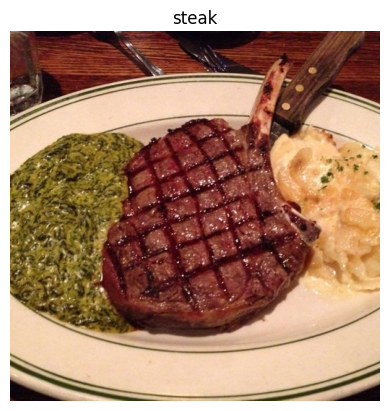

In [8]:
# View a random image from the training dataset
img = view_random_image(target_dir="pizza_steak/train/",
                        target_class="steak")

Image shape: (512, 382, 3)


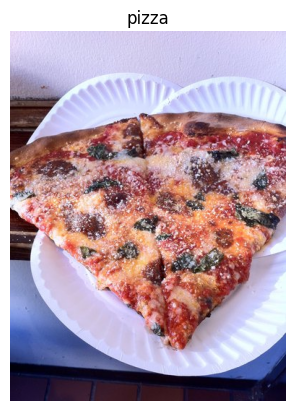

In [9]:
# View a random image from the training dataset
img = view_random_image(target_dir="pizza_steak/train/",
                        target_class="pizza")

In [10]:
# View the image shape
img.shape # returns (width, height, colour channels)

(512, 382, 3)

In [11]:
# Get all the pixel values between 0 & 1
img/255.

array([[[0.89803922, 0.83529412, 0.94117647],
        [0.89411765, 0.83137255, 0.9372549 ],
        [0.89803922, 0.83529412, 0.94901961],
        ...,
        [0.83137255, 0.80784314, 0.94901961],
        [0.83137255, 0.80784314, 0.94901961],
        [0.83529412, 0.81176471, 0.95294118]],

       [[0.91764706, 0.85490196, 0.96078431],
        [0.89019608, 0.82745098, 0.93333333],
        [0.89019608, 0.82745098, 0.94117647],
        ...,
        [0.85098039, 0.82745098, 0.96862745],
        [0.85490196, 0.83137255, 0.97254902],
        [0.85098039, 0.82745098, 0.96862745]],

       [[0.92156863, 0.85882353, 0.97254902],
        [0.88235294, 0.81960784, 0.93333333],
        [0.88627451, 0.82352941, 0.9372549 ],
        ...,
        [0.85882353, 0.83529412, 0.97647059],
        [0.85490196, 0.83921569, 0.97647059],
        [0.84313725, 0.82745098, 0.96470588]],

       ...,

       [[0.09411765, 0.03921569, 0.18039216],
        [0.09803922, 0.04313725, 0.18431373],
        [0.09803922, 0

# **A (typical) architecture of a convolutional neural network**

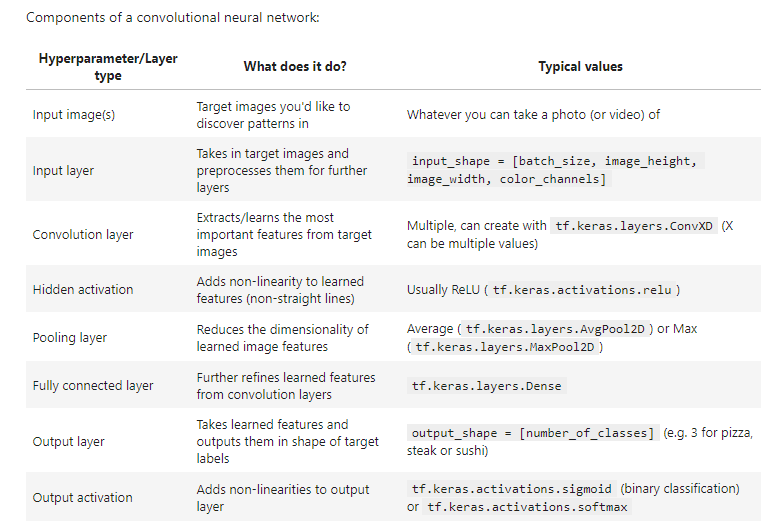

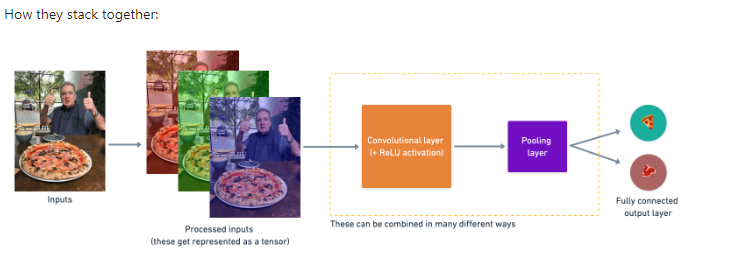

In [12]:
# Plot the validation and training data separately
def plot_loss_curves(history):
  """
  Returns separate loss curves for training and validation metrics.
  """
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  epochs = range(len(history.history['loss']))

  # Plot loss
  plt.plot(epochs, loss, label='training_loss')
  plt.plot(epochs, val_loss, label='val_loss')
  plt.title('Loss')
  plt.xlabel('Epochs')
  plt.legend()

  # Plot accuracy
  plt.figure()
  plt.plot(epochs, accuracy, label='training_accuracy')
  plt.plot(epochs, val_accuracy, label='val_accuracy')
  plt.title('Accuracy')
  plt.xlabel('Epochs')
  plt.legend();

In [13]:
from sklearn.metrics import classification_report

# **Data Preparation: An end-to-end example**

In [14]:
import tensorflow as tf
#from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.src.legacy.preprocessing.image import ImageDataGenerator

# Set the seed
tf.random.set_seed(42)

In [37]:
# Preprocess data (get all of the pixel values between 1 and 0, also called scaling/normalization)
train_datagen = ImageDataGenerator(rescale=1./255,
                                   fill_mode='nearest',
                                   rotation_range=40,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   validation_split=0.2)

test_datagen = ImageDataGenerator(rescale=1./255)



# Setup the train and test directories
train_dir = "pizza_steak/train/"
test_dir = "pizza_steak/test/"

In [38]:
# Import data from directories and turn it into batches
train_data = train_datagen.flow_from_directory(train_dir,
                                               batch_size=32, # number of images to process at a time
                                               target_size=(224, 224), # convert all images to be 224 x 224
                                               class_mode="binary", # type of problem we're working on
                                               shuffle=True,  # Pastikan ini aktif
                                               subset='training',
                                               seed=42)


valid_data = train_datagen.flow_from_directory(train_dir,
                                               batch_size=32,
                                               target_size=(224, 224),
                                               class_mode="binary",
                                               shuffle=True,  # Pastikan ini aktif
                                               subset='validation',
                                               seed=42)

test_data = test_datagen.flow_from_directory(test_dir,
                                               batch_size=32,
                                               target_size=(224, 224),
                                               class_mode="binary",
                                               shuffle=False,  #tambahan yuda
                                               seed=42)

Found 1200 images belonging to 2 classes.
Found 300 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


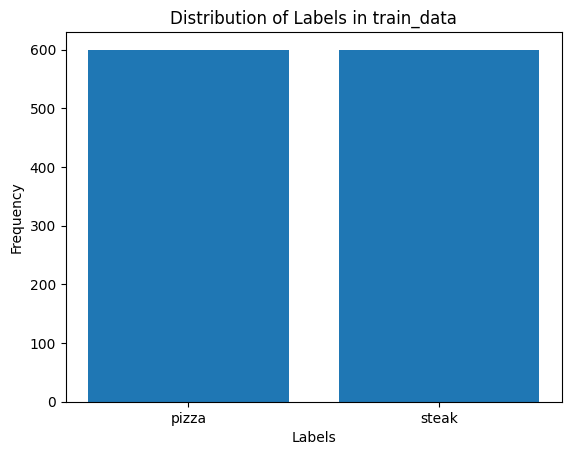

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil nama kelas dari train_data
class_indices = train_data.class_indices
class_names = list(class_indices.keys())  # Nama folder menjadi label kelas

# Ambil label dari test_data
labels = []
for i in range(len(train_data)):
    images, label_batch = train_data[i]
    labels.extend(label_batch)

# Hitung distribusi label
unique, counts = np.unique(labels, return_counts=True)

# Buat diagram batang dengan label kelas otomatis
plt.bar(unique, counts)
plt.xticks(unique, class_names)  # Gunakan nama folder sebagai label kelas
plt.xlabel('Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Labels in train_data')
plt.show()


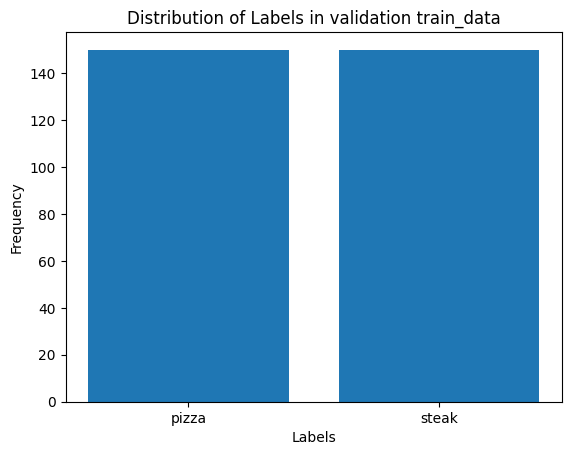

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil nama kelas dari valid_data
class_indices = valid_data.class_indices
class_names = list(class_indices.keys())  # Nama folder menjadi label kelas

# Ambil label dari test_data
labels = []
for i in range(len(valid_data)):
    images, label_batch = valid_data[i]
    labels.extend(label_batch)

# Hitung distribusi label
unique, counts = np.unique(labels, return_counts=True)

# Buat diagram batang dengan label kelas otomatis
plt.bar(unique, counts)
plt.xticks(unique, class_names)  # Gunakan nama folder sebagai label kelas
plt.xlabel('Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Labels in validation train_data')
plt.show()


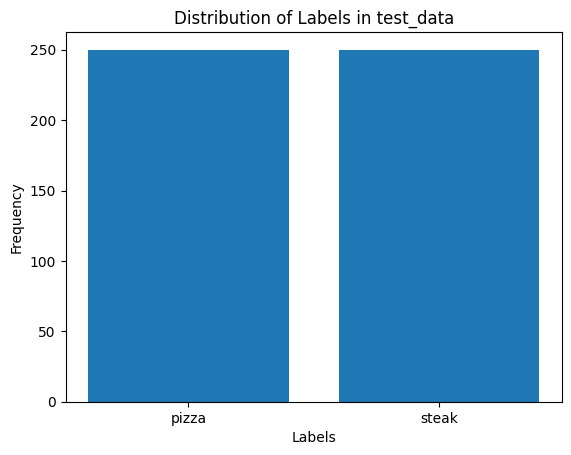

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil nama kelas dari test_data
class_indices = test_data.class_indices
class_names = list(class_indices.keys())  # Nama folder menjadi label kelas

# Ambil label dari test_data
labels = []
for i in range(len(test_data)):
    images, label_batch = test_data[i]
    labels.extend(label_batch)

# Hitung distribusi label
unique, counts = np.unique(labels, return_counts=True)

# Buat diagram batang dengan label kelas otomatis
plt.bar(unique, counts)
plt.xticks(unique, class_names)  # Gunakan nama folder sebagai label kelas
plt.xlabel('Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Labels in test_data')
plt.show()


In [ ]:
images, labels = next(train_data)
print(f"Batch shape: {images.shape}, Batch labels: {labels}")

Batch shape: (32, 224, 224, 3), Batch labels: [1. 0. 1. 0. 0. 1. 0. 1. 1. 0. 1. 1. 1. 0. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0.
 1. 1. 1. 0. 0. 0. 1. 1.]


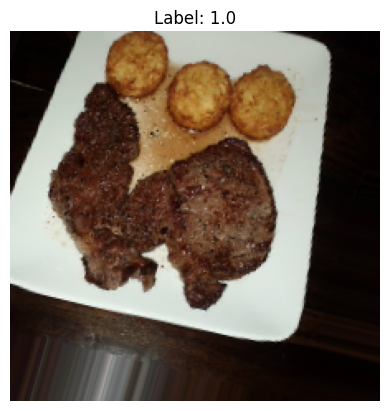

In [ ]:
import matplotlib.pyplot as plt

# Display the first image in the batch
plt.imshow(images[0])
plt.title(f"Label: {labels[0]}")
plt.axis("off")
plt.show()


# **Model 1: Tiny VGG**

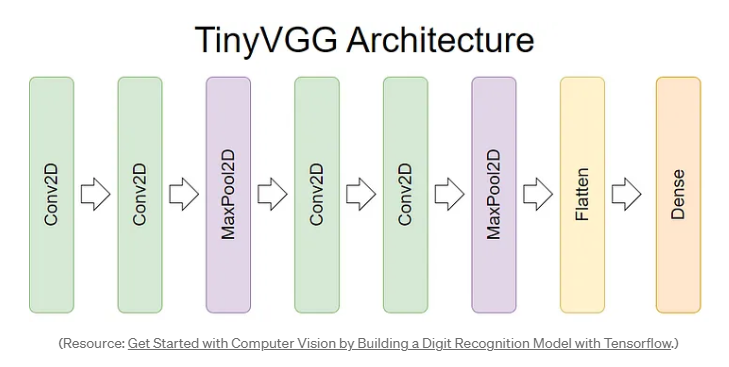

In [ ]:
# Create a CNN model (same as Tiny VGG - https://poloclub.github.io/cnn-explainer/)
model_1 = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(filters=10,
                         kernel_size=3, # can also be (3, 3)
                         activation="relu",
                         input_shape=(224, 224, 3)), # first layer specifies input shape (height, width, colour channels)
  tf.keras.layers.Conv2D(10, 3, activation="relu"),
  tf.keras.layers.MaxPool2D(pool_size=2, # pool_size can also be (2, 2)
                            padding="valid"), # padding can also be 'same'
  tf.keras.layers.Conv2D(10, 3, activation="relu"),
  tf.keras.layers.Conv2D(10, 3, activation="relu"), # activation='relu' == tf.keras.layers.Activations(tf.nn.relu)
  tf.keras.layers.MaxPool2D(2),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(1, activation="sigmoid") # binary activation output
])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Check out the layers in our model
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 10)        │             280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 220, 220, 10)        │             910 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 110, 110, 10)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 108, 108, 10)        │             910 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 106, 106, 10)        │             910 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 53, 53, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 28090)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │          28,091 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31,101 (121.49 KB)

 Trainable params: 31,101 (121.49 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the model
model_1.compile(loss="binary_crossentropy",
              optimizer=tf.keras.optimizers.Adam(),
              metrics=["accuracy"])

In [ ]:
import os

# Check the contents of the directories
print(f"Contents of train_dir: {os.listdir(train_dir)}")
print(f"Contents of test_dir: {os.listdir(test_dir)}")


Contents of train_dir: ['steak', 'pizza']
Contents of test_dir: ['steak', 'pizza']


In [ ]:
# Fit the model
history_1 = model_1.fit(train_data,
                        epochs=15,
                        steps_per_epoch = train_data.samples // train_data.batch_size,
                        validation_data=valid_data,
                        validation_steps = valid_data.samples // valid_data.batch_size
                        )

Epoch 1/15


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


37/37 ━━━━━━━━━━━━━━━━━━━━ 31s 581ms/step - accuracy: 0.5228 - loss: 0.6894 - val_accuracy: 0.6667 - val_loss: 0.6103
Epoch 2/15
 1/37 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.6562 - loss: 0.6214

/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 143ms/step - accuracy: 0.6562 - loss: 0.6214 - val_accuracy: 0.8333 - val_loss: 0.4770
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 25s 440ms/step - accuracy: 0.7031 - loss: 0.5675 - val_accuracy: 0.7431 - val_loss: 0.5368
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7812 - loss: 0.4805 - val_accuracy: 0.6667 - val_loss: 0.5597
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 476ms/step - accuracy: 0.7850 - loss: 0.4785 - val_accuracy: 0.7292 - val_loss: 0.5355
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7188 - loss: 0.5494 - val_accuracy: 0.8333 - val_loss: 0.4182
Epoch 7/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 459ms/step - accuracy: 0.7589 - loss: 0.4958 - val_accuracy: 0.7708 - val_loss: 0.4735
Epoch 8/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8438 - loss: 0.4780 - val_accuracy: 0.8333 - val_loss: 0.4109
Epoch 9/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 473ms/step - accuracy: 0.7820 - loss: 0.4709 - val_accuracy: 0.7917 - val_lo

In [ ]:
# Plot the validation and training data separately
def plot_loss_curves(history):
  """
  Returns separate loss curves for training and validation metrics.
  """
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  epochs = range(len(history.history['loss']))

  # Plot loss
  plt.plot(epochs, loss, label='training_loss')
  plt.plot(epochs, val_loss, label='val_loss')
  plt.title('Loss')
  plt.xlabel('Epochs')
  plt.legend()

  # Plot accuracy
  plt.figure()
  plt.plot(epochs, accuracy, label='training_accuracy')
  plt.plot(epochs, val_accuracy, label='val_accuracy')
  plt.title('Accuracy')
  plt.xlabel('Epochs')
  plt.legend();

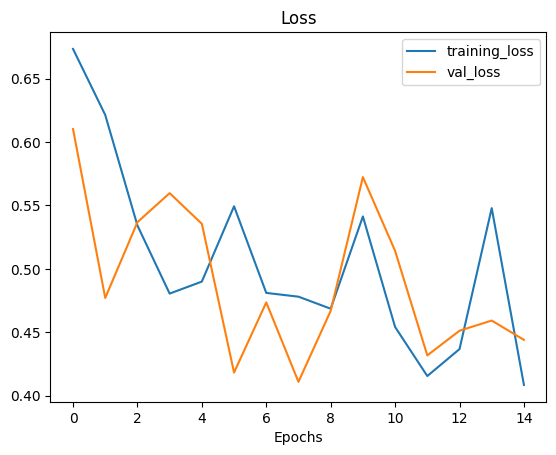

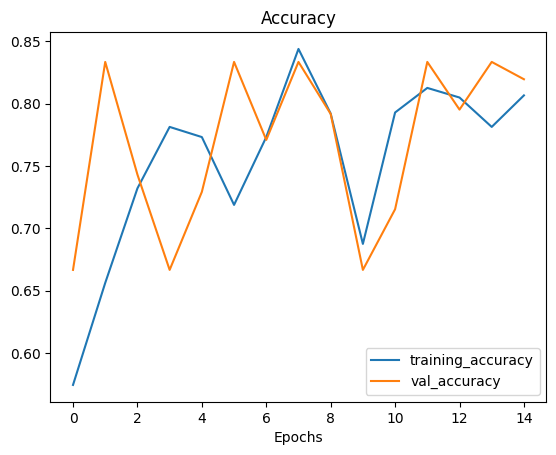

In [ ]:
# Check out the loss curves of model_1
plot_loss_curves(history_1)

**Evaluation Model 1**

In [ ]:
# Evaluasi model dengan data testing
test_loss, test_acc = model_1.evaluate(test_data)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - accuracy: 0.6689 - loss: 0.6842
Test Accuracy: 0.7860000133514404
Test Loss: 0.47310641407966614


In [ ]:
# Melakukan prediksi pada data testing
model1_predictions = model_1.predict(test_data)


16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step


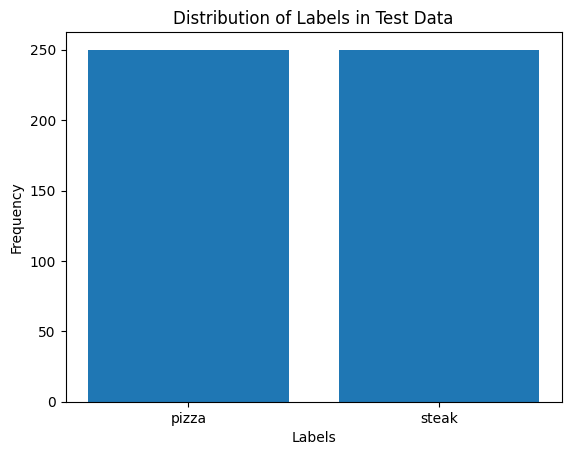

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil nama kelas dari test_data
class_indices = test_data.class_indices
class_names = list(class_indices.keys())  # Nama folder menjadi label kelas

# Ambil label dari test_data
labels = []
for i in range(len(test_data)):
    images, label_batch = test_data[i]
    labels.extend(label_batch)

# Hitung distribusi label
unique, counts = np.unique(labels, return_counts=True)

# Buat diagram batang dengan label kelas otomatis
plt.bar(unique, counts)
plt.xticks(unique, class_names)  # Gunakan nama folder sebagai label kelas
plt.xlabel('Labels')
plt.ylabel('Frequency')
plt.title('Distribution of Labels in Test Data')
plt.show()


In [ ]:
from sklearn.metrics import classification_report

# Karena ini adalah binary classification, kita ubah probabilitas menjadi kelas (0 atau 1)
predicted_classes = (model1_predictions > 0.5).astype("int32").flatten()

# Mendapatkan label asli dari data testing
true_classes = test_data.classes  # Label asli dari test data

# Mendapatkan nama kelas
class_labels = list(test_data.class_indices.keys())  # Nama kelas

# Tampilkan classification report
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

              precision    recall  f1-score   support

       pizza       0.94      0.61      0.74       250
       steak       0.71      0.96      0.82       250

    accuracy                           0.79       500
   macro avg       0.83      0.79      0.78       500
weighted avg       0.83      0.79      0.78       500



**Model Prediction Implementation**

Kamu bisa mencoba memprediksi data testing disini.

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Pilih indeks gambar yang ingin diprediksi
index = 486  # Ganti dengan indeks gambar yang Anda inginkan

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


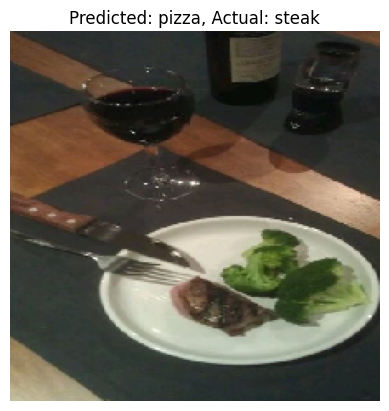

In [ ]:
# Ambil gambar dan label dari test_data
img_batch, label_batch = next(test_data)  # Mengambil batch gambar dari test_data

# Ambil gambar spesifik dari batch (misal gambar ke 'index' dalam batch)
img = img_batch[index % test_data.batch_size]  # Jika batch size adalah 32
label = label_batch[index % test_data.batch_size]  # Ambil label gambar yang sesuai

# Lakukan prediksi pada gambar yang diambil (tambahkan batch dimension)
predictions = model_1.predict(np.expand_dims(img, axis=0))  # Prediksi pada satu gambar
predicted_class = (predictions > 0.5).astype("int32")[0][0]  # Ubah prediksi menjadi kelas (0 atau 1)

# Mendapatkan nama kelas
class_labels = list(test_data.class_indices.keys())

# Tampilkan gambar beserta label asli dan prediksi
plt.imshow(img)
plt.title(f"Predicted: {class_labels[predicted_class]}, Actual: {class_labels[int(label)]}")
plt.axis('off')  # Matikan sumbu untuk tampilan yang lebih rapi
plt.show()

# **Model 2: ResNet50**

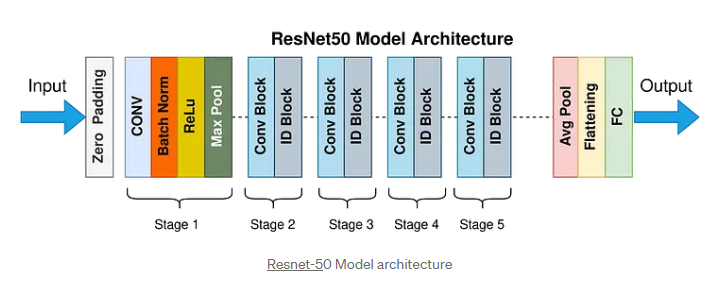

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

In [ ]:
# Load ResNet50 with pre-trained ImageNet weights, excluding the top layer
base_model = ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# Freeze the base model layers
base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
# Ensure the input shape is explicitly defined
inputs = tf.keras.layers.Input(shape=(224, 224, 3))

# Pass the inputs through the base model
x = base_model(inputs)

# Add a GlobalAveragePooling2D layer
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# x = tf.keras.layers.Dense(256, activation='relu')(x)

# x = tf.keras.layers.Dense(128, activation='relu')(x)

# Add a final dense layer for binary classification
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

# Create the final model
model_resnet = tf.keras.models.Model(inputs, outputs)

In [ ]:
# Compile the model
model_resnet.compile(loss='binary_crossentropy',
                     optimizer=tf.keras.optimizers.Adam(),
                     metrics=['accuracy'])

In [ ]:
# Model summary
model_resnet.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,145,281 (92.11 MB)

 Trainable params: 557,569 (2.13 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# Fit the model
history_2 = model_resnet.fit(train_data,
                        epochs=10,
                        steps_per_epoch = train_data.samples // train_data.batch_size,
                        validation_data=valid_data,
                        validation_steps = valid_data.samples // valid_data.batch_size
                        )

Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 27s 662ms/step - accuracy: 0.5234 - loss: 0.7183 - val_accuracy: 0.6042 - val_loss: 0.6793
Epoch 2/10
 1/37 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - accuracy: 0.6250 - loss: 0.6535

/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.6250 - loss: 0.6535 - val_accuracy: 0.3333 - val_loss: 0.6812
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 474ms/step - accuracy: 0.5746 - loss: 0.6761 - val_accuracy: 0.5556 - val_loss: 0.6711
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5625 - loss: 0.6634 - val_accuracy: 0.5833 - val_loss: 0.6562
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 40s 476ms/step - accuracy: 0.6161 - loss: 0.6550 - val_accuracy: 0.5174 - val_loss: 0.7329
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5312 - loss: 0.7078 - val_accuracy: 0.5833 - val_loss: 0.6348
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 23s 534ms/step - accuracy: 0.5261 - loss: 0.6914 - val_accuracy: 0.5486 - val_loss: 0.6976
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5000 - loss: 0.6949 - val_accuracy: 0.8333 - val_loss: 0.5497
Epoch 9/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 46s 677ms/step - accuracy: 0.6066 - loss: 0.6533 - val_accuracy: 0.5069 - val_los

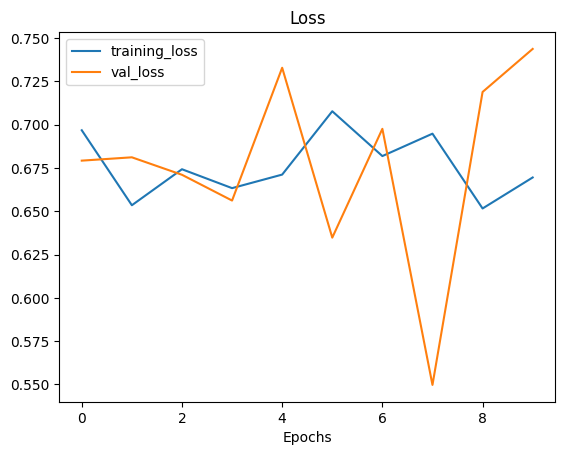

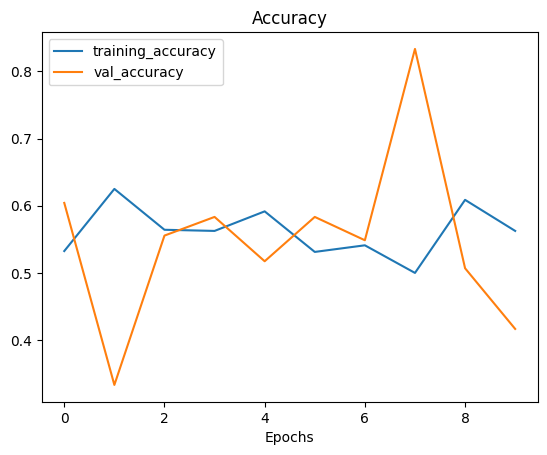

In [ ]:
# Check out the loss curves of model_1
plot_loss_curves(history_2)

**Evaluation Model 2: Resnet**

In [ ]:
# Evaluasi model dengan data testing
test_loss, test_acc = model_resnet.evaluate(test_data)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 345ms/step - accuracy: 0.8046 - loss: 0.4455
Test Accuracy: 0.5120000243186951
Test Loss: 0.6713905930519104


In [ ]:
# Melakukan prediksi pada data testing
model2_predictions = model_resnet.predict(test_data)

16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 283ms/step


In [ ]:
# Karena ini adalah binary classification, kita ubah probabilitas menjadi kelas (0 atau 1)
predicted_classes2 = (model2_predictions > 0.5).astype("int32").flatten()

# Mendapatkan label asli dari data testing
true_classes = test_data.classes  # Label asli dari test data

# Mendapatkan nama kelas
class_labels = list(test_data.class_indices.keys())  # Nama kelas

# Tampilkan classification report
print(classification_report(true_classes, predicted_classes2, target_names=class_labels))

              precision    recall  f1-score   support

       pizza       0.51      1.00      0.67       250
       steak       0.88      0.03      0.05       250

    accuracy                           0.51       500
   macro avg       0.69      0.51      0.36       500
weighted avg       0.69      0.51      0.36       500



# **Model 3: EfficientNetB3**

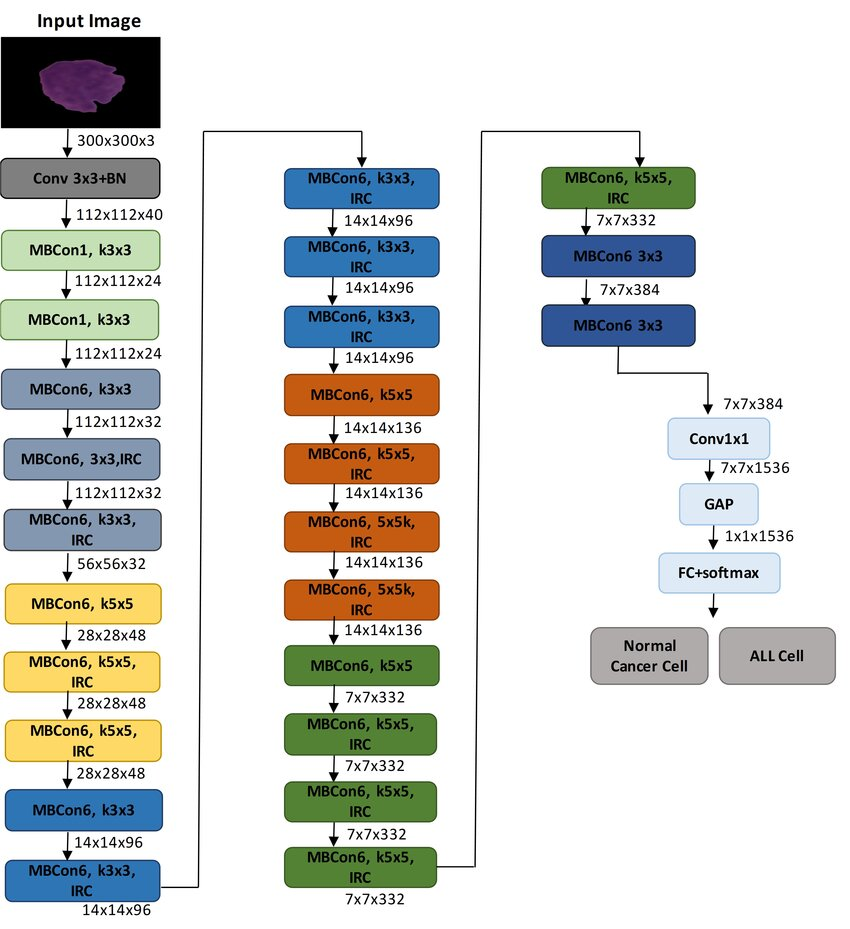

In [15]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input

**Preprocessing Khusus Efficient**

In [16]:
# Preprocess data (get all of the pixel values between 1 and 0, also called scaling/normalization)
train_datagen_punyaEfficientNet = ImageDataGenerator(#rescale=1./255,
                                   preprocessing_function = preprocess_input,
                                   fill_mode='nearest',
                                   rotation_range=20,
                                   width_shift_range=0.1,
                                   height_shift_range=0.1,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   validation_split=0.2
                                   )

test_datagen_punyaEfficientNet = ImageDataGenerator(#rescale=1./255,
                                  preprocessing_function = preprocess_input)

In [17]:
# Setup the train and test directories
train_dir = "pizza_steak/train/"
test_dir = "pizza_steak/test/"

In [18]:
# Import data from directories and turn it into batches
train_data_punyaEfficientNet = train_datagen_punyaEfficientNet.flow_from_directory(train_dir,
                                               batch_size=32, # number of images to process at a time
                                               target_size=(224, 224), # convert all images to be 224 x 224
                                               class_mode="binary", # type of problem we're working on
                                               shuffle=True,  # Pastikan ini aktif
                                               subset='training',
                                               seed=42)


valid_data_punyaEfficientNet = train_datagen_punyaEfficientNet.flow_from_directory(train_dir,
                                               batch_size=32,
                                               target_size=(224, 224),
                                               class_mode="binary",
                                               shuffle=True,  # Pastikan ini aktif
                                               subset='validation',
                                               seed=42)

test_data_punyaEfficientNet = test_datagen_punyaEfficientNet.flow_from_directory(test_dir,
                                               batch_size=32,
                                               target_size=(224, 224),
                                               class_mode="binary",
                                               shuffle=False,  #tambahan yuda
                                               seed=42)

Found 1200 images belonging to 2 classes.
Found 300 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


In [19]:
# Load EfficientNetB3 with pre-trained ImageNet weights, excluding the top layer
base_model3 = EfficientNetB3(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# Unfreeze the top layers of the EfficientNetB3 model
base_model3.trainable = False  #freeze all layers or some layers

# Optionally, Unfreeze the last 5 layers
for layer in base_model3.layers[-5:]:
    layer.trainable = True

In [20]:
# Print the total number of layers
print(f"Total number of layers in EfficientNetB3: {len(base_model3.layers)}")

Total number of layers in EfficientNetB3: 385


In [ ]:
# # Define the input shape explicitly
# inputs = tf.keras.layers.Input(shape=(224, 224, 3))

# # Pass the inputs through the base model
# x = base_model(inputs)

# # Add a GlobalAveragePooling2D layer
# x = tf.keras.layers.GlobalAveragePooling2D()(x)

# # Add a final dense layer for binary classification
# outputs = tf.keras.layers.Dense(2, activation='softmax')(x)

# # Create the final model
# model_efficientnet = tf.keras.models.Model(inputs, outputs)

In [21]:
# Define the input shape explicitly
inputs = tf.keras.layers.Input(shape=(224, 224, 3))

# Pass the inputs through the base model (EfficientNetB3)
x = base_model3(inputs)

# Add a GlobalAveragePooling2D layer
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Flatten the output instead of using GlobalAveragePooling2D
# x = tf.keras.layers.Flatten()(x)

# Add the first dense layer
x = tf.keras.layers.Dense(1024, activation='relu')(x)  # Dense layer with 128 units and ReLU activation


# Add the second dense layer
x = tf.keras.layers.Dense(1024, activation='relu')(x)  # Dense layer with 128 units and ReLU activation

# Add a Dropout layer to prevent overfitting
# x = tf.keras.layers.Dropout(0.2)(x)  # Dropout layer with 20% rate

# Add the third dense layer
x = tf.keras.layers.Dense(1024, activation='relu')(x)  # Dense layer with 128 units and ReLU activation

# Add a Dropout layer to prevent overfitting
x = tf.keras.layers.Dropout(0.2)(x)  # Dropout layer with 20% rate

# Add the fourth dense layer
x = tf.keras.layers.Dense(1024, activation='relu')(x)  # Dense layer with 128 units and ReLU activation

# Add the final dense layer for binary classification with sigmoid activation
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

# Create the final model
model_efficientnet = tf.keras.models.Model(inputs, outputs)



In [22]:
# Compile the model
model_efficientnet.compile(#optimizer='adam',
                           optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                           loss='binary_crossentropy',
                           metrics=['accuracy'])

In [23]:
# Summary of the model
model_efficientnet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 7, 7, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,573,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,507,248 (59.16 MB)

 Trainable params: 5,316,609 (20.28 MB)

 Non-trainable params: 10,190,639 (38.87 MB)

In [24]:
print("train_data.samples = ", train_data_punyaEfficientNet.samples)
print("train_data.batch_size = ", train_data_punyaEfficientNet.batch_size)
print("valid_data.samples = ", valid_data_punyaEfficientNet.samples)
print("valid_data.batch_size = ", valid_data_punyaEfficientNet.batch_size)

train_data.samples =  1200
train_data.batch_size =  32
valid_data.samples =  300
valid_data.batch_size =  32


In [27]:
# Fit the model
history_3 = model_efficientnet.fit(train_data_punyaEfficientNet,
                        epochs=15,
                        steps_per_epoch = train_data_punyaEfficientNet.samples // train_data_punyaEfficientNet.batch_size,
                        validation_data=valid_data_punyaEfficientNet,
                        validation_steps = valid_data_punyaEfficientNet.samples // valid_data_punyaEfficientNet.batch_size
                        )

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.6147 - loss: 0.6614 - val_accuracy: 0.9340 - val_loss: 0.5757
Epoch 2/15
 1/37 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.9062 - loss: 0.5718

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 120ms/step - accuracy: 0.9062 - loss: 0.5718 - val_accuracy: 0.9340 - val_loss: 0.5736
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 537ms/step - accuracy: 0.8839 - loss: 0.5379 - val_accuracy: 0.9514 - val_loss: 0.4116
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 0.8750 - loss: 0.4552 - val_accuracy: 0.9583 - val_loss: 0.4084
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 497ms/step - accuracy: 0.9510 - loss: 0.3617 - val_accuracy: 0.9653 - val_loss: 0.2319
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 1.0000 - loss: 0.1933 - val_accuracy: 0.9688 - val_loss: 0.2276
Epoch 7/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 38s 527ms/step - accuracy: 0.9690 - loss: 0.2018 - val_accuracy: 0.9549 - val_loss: 0.1542
Epoch 8/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 1.0000 - loss: 0.0754 - val_accuracy: 0.9549 - val_loss: 0.1416
Epoch 9/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 569ms/step - accuracy: 0.9658 - loss: 0.1241 - val_accuracy: 0.9653 - v

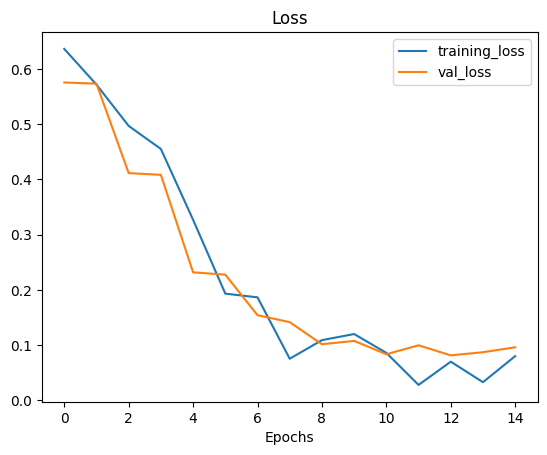

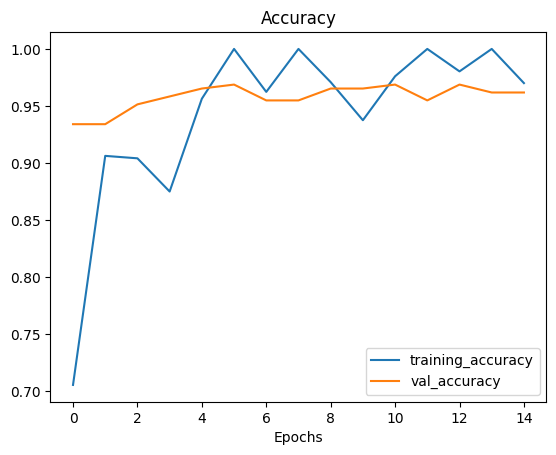

In [28]:
# Check out the loss curves of model_1
plot_loss_curves(history_3)

**Evaluation Model 32: EfficientNetB3**

In [29]:
# Evaluasi model dengan data testing
test_loss, test_acc = model_efficientnet.evaluate(test_data_punyaEfficientNet)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9929 - loss: 0.0220
Test Accuracy: 0.9940000176429749
Test Loss: 0.022997412830591202


In [30]:
# Melakukan prediksi pada data testing
model3_predictions = model_efficientnet.predict(test_data_punyaEfficientNet)

16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 730ms/step


In [32]:
# Karena ini adalah binary classification, kita ubah probabilitas menjadi kelas (0 atau 1)
predicted_classes3 = (model3_predictions > 0.5).astype("int32").flatten()

# Mendapatkan label asli dari data testing
true_classes = test_data_punyaEfficientNet.classes  # Label asli dari test data

# Mendapatkan nama kelas
class_labels = list(test_data_punyaEfficientNet.class_indices.keys())  # Nama kelas

# Tampilkan classification report
print(classification_report(true_classes, predicted_classes3, target_names=class_labels, zero_division=1))

              precision    recall  f1-score   support

       pizza       1.00      0.99      0.99       250
       steak       0.99      1.00      0.99       250

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500



In [34]:
# Melakukan prediksi pada data testing
model3_predictions = model_efficientnet.predict(train_data_punyaEfficientNet)

38/38 ━━━━━━━━━━━━━━━━━━━━ 23s 607ms/step


In [35]:
index = 150

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


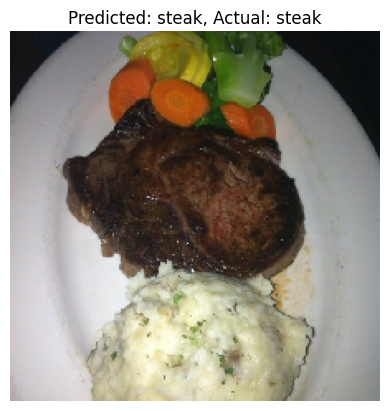

In [50]:
# Ambil gambar dan label dari test_data
img_batch, label_batch = next(test_data_punyaEfficientNet)  # Mengambil batch gambar dari test_data

# Ambil gambar spesifik dari batch (misal gambar ke 'index' dalam batch)
img = img_batch[index % test_data_punyaEfficientNet.batch_size]  # Jika batch size adalah 32
label = label_batch[index % test_data_punyaEfficientNet.batch_size]  # Ambil label gambar yang sesuai

# Lakukan prediksi pada gambar yang diambil (tambahkan batch dimension)
predictions = model_efficientnet.predict(np.expand_dims(img, axis=0))  # Prediksi pada satu gambar
predicted_class = (predictions > 0.5).astype("int32")[0][0]  # Ubah prediksi menjadi kelas (0 atau 1)

# Mendapatkan nama kelas
class_labels = list(test_data_punyaEfficientNet.class_indices.keys())

# Tampilkan gambar beserta label asli dan prediksi
plt.imshow(img/ 255.0)
plt.title(f"Predicted: {class_labels[predicted_class]}, Actual: {class_labels[int(label)]}")
plt.axis('off')  # Matikan sumbu untuk tampilan yang lebih rapi
plt.show()


# **Model 4: InceptionV3**

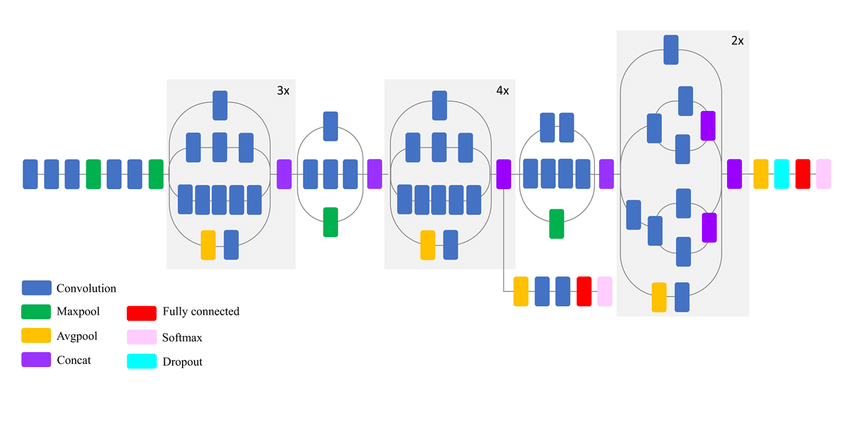

In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [ ]:
# Load the pre-trained InceptionV3 model
base_model4 = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model layers
base_model4.trainable = False

In [ ]:
# Print the total number of layers
print(f"Total number of layers in InceptionV3: {len(base_model4.layers)}")

Total number of layers in InceptionV3: 311


In [ ]:
# Add new layers on top for binary classification (steak vs. pizza)
x = base_model4.output
x = GlobalAveragePooling2D()(x)  # Global Average Pooling
x = Dense(256, activation='relu')(x)  # Fully connected layer
# Add the second dense layer
x = tf.keras.layers.Dense(128, activation='relu')(x)  # Dense layer with 128 units and ReLU activation
# Add a Dropout layer to prevent overfitting
x = tf.keras.layers.Dropout(0.2)(x)  # Dropout layer with 20% rate
predictions = Dense(1, activation='sigmoid')(x)  # Binary classification layer


In [ ]:
# Create the model
model4 = Model(inputs=base_model4.input, outputs=predictions)

In [ ]:
# Compile the model
model4.compile(optimizer=Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Summary of the model
model4.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6             │ (None, 224, 224, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_98 (Conv2D)        │ (None, 111, 111, 32)   │            864 │ input_layer_6[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_94    │ (None, 111, 111, 32)   │             96 │ conv2d_98[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_94             │ (None, 111, 111, 32)   │              0 │ batch_normalization_9… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_99 (Conv2D)        │ (None, 109, 109, 32)   │          9,216 │ activation_94[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_95    │ (None, 109, 109, 32)   │             96 │ conv2d_99[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_95             │ (None, 109, 109, 32)   │              0 │ batch_normalization_9… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_100 (Conv2D)       │ (None, 109, 109, 64)   │         18,432 │ activation_95[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_96    │ (None, 109, 109, 64)   │            192 │ conv2d_100[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_96             │ (None, 109, 109, 64)   │              0 │ batch_normalization_9… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_6           │ (None, 54, 54, 64)     │              0 │ activation_96[0][0]    │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_101 (Conv2D)       │ (None, 54, 54, 80)     │          5,120 │ max_pooling2d_6[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_97    │ (None, 54, 54, 80)     │            240 │ conv2d_101[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_97             │ (None, 54, 54, 80)     │              0 │ batch_normalization_9… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_102 (Conv2D)  

 Total params: 22,360,353 (85.30 MB)

 Trainable params: 557,569 (2.13 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
# Fit the model
history_4 = model4.fit(train_data,
                        epochs=15,
                        steps_per_epoch = train_data.samples // train_data.batch_size,
                        validation_data=valid_data,
                        validation_steps = valid_data.samples // valid_data.batch_size
                        )

Epoch 1/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 40s 706ms/step - accuracy: 0.7559 - loss: 0.5692 - val_accuracy: 0.9167 - val_loss: 0.1826
Epoch 2/15
 1/37 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 1.0000 - loss: 0.1361

/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 1.0000 - loss: 0.1361 - val_accuracy: 1.0000 - val_loss: 0.0724
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 456ms/step - accuracy: 0.9307 - loss: 0.1669 - val_accuracy: 0.9375 - val_loss: 0.1460
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9375 - loss: 0.1331 - val_accuracy: 0.8333 - val_loss: 0.2284
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 20s 467ms/step - accuracy: 0.9376 - loss: 0.1425 - val_accuracy: 0.9340 - val_loss: 0.1595
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8438 - loss: 0.5440 - val_accuracy: 1.0000 - val_loss: 0.0310
Epoch 7/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 451ms/step - accuracy: 0.9571 - loss: 0.1190 - val_accuracy: 0.9340 - val_loss: 0.1471
Epoch 8/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8438 - loss: 0.2588 - val_accuracy: 0.9167 - val_loss: 0.2384
Epoch 9/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 21s 471ms/step - accuracy: 0.9520 - loss: 0.1326 - val_accuracy: 0.9375 - val_lo

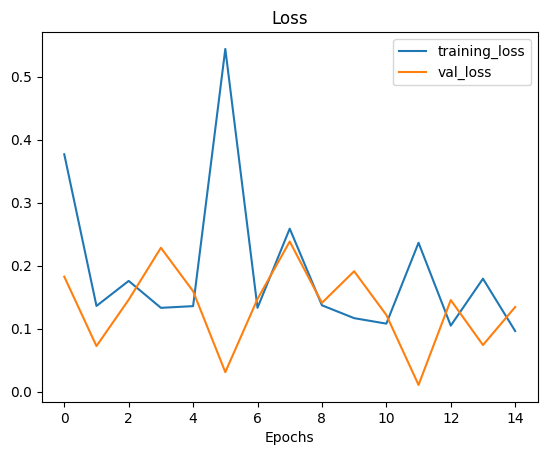

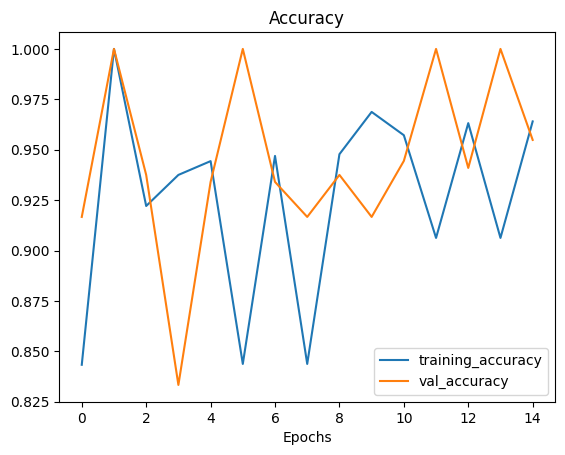

In [ ]:
# Check out the loss curves of model_1
plot_loss_curves(history_4)

**Evaluation Model 32: InceptionV3**

In [ ]:
# Evaluasi model dengan data testing
test_loss, test_acc = model4.evaluate(test_data)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 284ms/step - accuracy: 0.9937 - loss: 0.0364
Test Accuracy: 0.9919999837875366
Test Loss: 0.03669087961316109


In [ ]:
# Melakukan prediksi pada data testing
model4_predictions = model4.predict(test_data)

16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 357ms/step


In [ ]:
# Karena ini adalah binary classification, kita ubah probabilitas menjadi kelas (0 atau 1)
predicted_classes4 = (model4_predictions > 0.5).astype("int32").flatten()

# Mendapatkan label asli dari data testing
true_classes = test_data.classes  # Label asli dari test data

# Mendapatkan nama kelas
class_labels = list(test_data.class_indices.keys())  # Nama kelas

# Tampilkan classification report
print(classification_report(true_classes, predicted_classes4, target_names=class_labels, zero_division=1))

              precision    recall  f1-score   support

       pizza       0.99      0.99      0.99       250
       steak       0.99      0.99      0.99       250

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500

